Chapter 6: Accounting Data Analytics

6.2 Detecting Patterns in Financial Statements

Objective

Financial analysts frequently use historical financial statements to forecast the future performance of companies.

However, forecasting financial statements is not simply about extending past trends into the future. Analysts must examine whether the financial performance observed in the past is likely to continue.

In this exercise, we will investigate two questions :

Revenue Growth: How can we forecast the revenue growth rate of a company currently growing at a certain percentage? for our data set (20%-40%) How long can such growth continue?

Operating Margin: How can we forecast a company's operating margin when it has recently been unusually high or low?

In [3]:

# ============================================================
# Import the required Python libraries.
#
# pandas     : Reading and analysing financial statement data.
# numpy      : Performing numerical calculations.
# matplotlib : Creating graphs to visualise financial patterns.
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:

# ============================================================
# Mount Google Drive.
#
# Our Historical Financial Dataset was saved in Google Drive
# during the previous practical exercises.
#
# Mounting Drive allows Google Colab to access the dataset
# without uploading the CSV again for every session.
# ============================================================

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [5]:

# ============================================================
# Load the Historical Financial Dataset.
#
# pd.read_csv() reads the CSV file and converts it into
# a pandas DataFrame.
#
# A DataFrame is a table containing rows and columns.
# ============================================================

historical_df = pd.read_csv(
    "/content/drive/MyDrive/Anusha/Financial Analytics/Data/Historical_Financial_Data.csv"
)

# Display the first five rows of the dataset.
historical_df.head()


,Company,Ticker,Sector,Industry,Financial Year,Revenue,Gross Profit,Operating Income,EBIT,EBITDA,...,Current Assets,Cash,Total Liabilities,Total Debt,Shareholders Equity,Operating Cash Flow,Investing Cash Flow,Financing Cash Flow,Capital Expenditure,Free Cash Flow
0,Adani Enterprises Limited,ADANIENT.NS,Energy,Thermal Coal,2026,1.002670e+12,2.620093e+11,8.437760e+10,1.991757e+11,2.605291e+11,...,6.117604e+11,6.266670e+10,1.724221e+12,1.066218e+12,8.092595e+11,2.356910e+10,-2.843801e+11,2.848447e+11,-3.336912e+11,-3.101221e+11
1,Adani Enterprises Limited,ADANIENT.NS,Energy,Thermal Coal,2025,9.771108e+11,3.276082e+11,1.044309e+11,1.536634e+11,1.957767e+11,...,4.094422e+11,3.105780e+10,1.416651e+12,9.147260e+11,5.031397e+11,4.513100e+10,-2.696661e+11,2.265534e+11,-2.987914e+11,-2.536604e+11
2,Adani Enterprises Limited,ADANIENT.NS,Energy,Thermal Coal,2024,9.631615e+11,3.114884e+11,9.012870e+10,8.644370e+10,1.168652e+11,...,3.702690e+11,2.306550e+10,1.165456e+12,6.531015e+11,3.907609e+11,1.031219e+11,-1.908218e+11,8.878680e+10,-2.236591e+11,-1.205372e+11
3,Adani Enterprises Limited,ADANIENT.NS,Energy,Thermal Coal,2023,1.273896e+12,2.061800e+11,6.827980e+10,6.241290e+10,8.677430e+10,...,3.728228e+11,1.882330e+10,1.035978e+12,5.301260e+11,3.305101e+11,1.762646e+11,-1.686009e+11,-1.197520e+10,-1.472472e+11,2.901740e+10
4,Adani Ports and Special Economic Zone Limited,ADANIPORTS.NS,Industrials,Marine Shipping,2026,3.873577e+11,2.343314e+11,1.745082e+11,1.859993e+11,2.411731e+11,...,2.197483e+11,5.161550e+10,8.633328e+11,6.323616e+11,9.612530e+11,2.035625e+11,-1.319070e+11,-5.483400e+10,-1.532031e+11,5.035940e+10


Question 1: Revenue Growth Analysis
 How do we forecast the revenue growth rate of a company currently growing at a rate exceeding 100%? For how long can this growth continue?
 Before forecasting revenue growth, we need to calculate historical annual revenue growth for each company.

To do this, we will:

Select the relevant financial variables.

Arrange observations by company and financial year.

Calculate the percentage change in revenue from one year to the next.

Examine historical growth patterns.

Revenue Growth Formula

[
\text{Revenue Growth (%)} = \frac{\text{Current Year Revenue}-\text{Previous Year Revenue}}{\text{Previous Year Revenue}}\times100

In [6]:
# Select the financial variables required for revenue growth analysis.
# historical_df is the original dataset we uploaded.
# We need company identifiers, financial years, and revenue figures.

revenue_df = historical_df[
    ['Ticker', 'Company', 'Sector', 'Financial Year', 'Revenue']
].copy()

# .copy() creates a separate DataFrame without changing the original.

# .head(10) displays the first 10 rows of our selected data.
revenue_df.head(10)


,Ticker,Company,Sector,Financial Year,Revenue
0,ADANIENT.NS,Adani Enterprises Limited,Energy,2026,1.002670e+12
1,ADANIENT.NS,Adani Enterprises Limited,Energy,2025,9.771108e+11
2,ADANIENT.NS,Adani Enterprises Limited,Energy,2024,9.631615e+11
3,ADANIENT.NS,Adani Enterprises Limited,Energy,2023,1.273896e+12
4,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2026,3.873577e+11
5,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2025,3.047533e+11
6,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2024,2.671056e+11
7,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2023,2.085191e+11
8,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2022,NaN
9,APOLLOHOSP.NS,Apollo Hospitals Enterprise Limited,Healthcare,2026,2.522850e+11


In [7]:

# STEP 2: Arrange the financial data in chronological order

# .sort_values() arranges rows based on the selected columns.
# 'Ticker' groups each company's financial records together.
# 'Financial Year' arranges each company's records from oldest to newest.

revenue_df = revenue_df.sort_values(
    by=['Ticker', 'Financial Year']
).reset_index(drop=True)

# .reset_index(drop=True) gives the sorted rows new sequential numbers.
# drop=True prevents the old row numbers from becoming another column.

# Display the first 15 rows to verify the sorting.
revenue_df.head(15)


,Ticker,Company,Sector,Financial Year,Revenue
0,ADANIENT.NS,Adani Enterprises Limited,Energy,2023,1.273896e+12
1,ADANIENT.NS,Adani Enterprises Limited,Energy,2024,9.631615e+11
2,ADANIENT.NS,Adani Enterprises Limited,Energy,2025,9.771108e+11
3,ADANIENT.NS,Adani Enterprises Limited,Energy,2026,1.002670e+12
4,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2022,NaN
5,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2023,2.085191e+11
6,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2024,2.671056e+11
7,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2025,3.047533e+11
8,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2026,3.873577e+11
9,APOLLOHOSP.NS,Apollo Hospitals Enterprise Limited,Healthcare,2022,NaN


In [8]:

# STEP 3: Retrieve each company's previous-year revenue

# groupby('Ticker') groups the records separately for each company.
# shift(1) retrieves the previous available observation's value.

revenue_df['Previous_Revenue'] = (
    revenue_df.groupby('Ticker')['Revenue'].shift(1)
)

# Retrieve the previous available financial year.
# This helps verify that we are comparing consecutive years.

revenue_df['Previous_Year'] = (
    revenue_df.groupby('Ticker')['Financial Year'].shift(1)
)

# Display current and previous-year revenue side by side.
revenue_df[
    ['Ticker', 'Financial Year', 'Revenue',
     'Previous_Year', 'Previous_Revenue']
].head(15)


,Ticker,Financial Year,Revenue,Previous_Year,Previous_Revenue
0,ADANIENT.NS,2023,1.273896e+12,NaN,NaN
1,ADANIENT.NS,2024,9.631615e+11,2023.0,1.273896e+12
2,ADANIENT.NS,2025,9.771108e+11,2024.0,9.631615e+11
3,ADANIENT.NS,2026,1.002670e+12,2025.0,9.771108e+11
4,ADANIPORTS.NS,2022,NaN,NaN,NaN
5,ADANIPORTS.NS,2023,2.085191e+11,2022.0,NaN
6,ADANIPORTS.NS,2024,2.671056e+11,2023.0,2.085191e+11
7,ADANIPORTS.NS,2025,3.047533e+11,2024.0,2.671056e+11
8,ADANIPORTS.NS,2026,3.873577e+11,2025.0,3.047533e+11
9,APOLLOHOSP.NS,2022,NaN,NaN,NaN


In [9]:

# STEP 4: Calculate annual revenue growth for each company

# First, check whether the current and previous financial
# years are consecutive (e.g., 2024 - 2023 = 1).

consecutive_year = (
    revenue_df['Financial Year'] -
    revenue_df['Previous_Year'] == 1
)

# Check that previous-year revenue is positive
# and current-year revenue is not missing.
# & means AND: both conditions must be satisfied.
# .notna() checks whether a value is available.

valid_revenue = (
    (revenue_df['Previous_Revenue'] > 0) &
    (revenue_df['Revenue'].notna())
)

# Revenue Growth (%) =
# [(Current Revenue - Previous Revenue) / Previous Revenue] * 100

# np.where() applies a condition:
# If both checks pass, calculate revenue growth.
# Otherwise, assign NaN (missing value).

revenue_df['Revenue_Growth'] = np.where(
    consecutive_year & valid_revenue,
    (
        (revenue_df['Revenue'] -
         revenue_df['Previous_Revenue'])
        / revenue_df['Previous_Revenue']
    ) * 100,
    np.nan
)

# Display the results rounded to two decimal places.

revenue_df[
    ['Ticker', 'Financial Year', 'Revenue',
     'Previous_Revenue', 'Revenue_Growth']
].head(20).round(2)


,Ticker,Financial Year,Revenue,Previous_Revenue,Revenue_Growth
0,ADANIENT.NS,2023,1.273896e+12,NaN,NaN
1,ADANIENT.NS,2024,9.631615e+11,1.273896e+12,-24.39
2,ADANIENT.NS,2025,9.771108e+11,9.631615e+11,1.45
3,ADANIENT.NS,2026,1.002670e+12,9.771108e+11,2.62
4,ADANIPORTS.NS,2022,NaN,NaN,NaN
5,ADANIPORTS.NS,2023,2.085191e+11,NaN,NaN
6,ADANIPORTS.NS,2024,2.671056e+11,2.085191e+11,28.10
7,ADANIPORTS.NS,2025,3.047533e+11,2.671056e+11,14.09
8,ADANIPORTS.NS,2026,3.873577e+11,3.047533e+11,27.11
9,APOLLOHOSP.NS,2022,NaN,NaN,NaN


In [10]:

# STEP 5: Understand the distribution of revenue growth

# .dropna() removes missing growth values from the analysis.
growth_values = revenue_df['Revenue_Growth'].dropna()

# len() counts the number of valid observations.
print("Valid observations:", len(growth_values))

# .mean() calculates the average revenue growth.
print("Mean growth:", round(growth_values.mean(), 2), "%")

# .median() identifies the middle growth rate.
# It is less affected by extreme values than the mean.
print("Median growth:", round(growth_values.median(), 2), "%")

# .std() measures variation in revenue growth.
print("Standard deviation:",
      round(growth_values.std(), 2), "percentage points")

# .min() and .max() identify the lowest and highest growth rates.
print("Minimum growth:", round(growth_values.min(), 2), "%")
print("Maximum growth:", round(growth_values.max(), 2), "%")


Valid observations: 145
Mean growth: 51.24 %
Median growth: 10.79 %
Standard deviation: 449.79 percentage points
Minimum growth: -24.39 %
Maximum growth: 5424.3 %


From our revenue growth distribution (145 observations), we understood:
- Mean: 51.24% — unusually high because of extreme observations.
- Median: 10.79% — a more representative measure of typical revenue growth.
- Maximum: 5,424.3% — indicates an extreme outlier.
- Minimum: Shows that some companies experienced revenue contraction.
Key takeaway: Revenue growth is highly right-skewed. A few exceptionally high growth rates pull the average upward, making it misleading as a measure of typical growth.

This also helps explain why we examine a specific growth range (20%–40%) rather than using the overall average to forecast a high-growth company's revenue.

In [11]:

# STEP 6: Identify historical observations with 20%-40% growth

# Define the lower and upper limits of our growth range.
lower_growth = 20
upper_growth = 40

# .between() selects growth rates from 20% to 40%,
# including both 20% and 40%.
# The square brackets filter the rows that satisfy this condition.

high_growth_df = revenue_df[
    revenue_df['Revenue_Growth'].between(
        lower_growth, upper_growth
    )
].copy()

# Count the number of selected company-year observations.
print("Observations with 20%-40% growth:", len(high_growth_df))

# Display the company, year, and calculated growth.
# .round(2) displays values to two decimal places.
high_growth_df[
    ['Ticker', 'Company', 'Financial Year', 'Revenue_Growth']
].round(2)


Observations with 20%-40% growth: 20


,Ticker,Company,Financial Year,Revenue_Growth
6,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,2024,28.10
8,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,2026,27.11
20,AXISBANK.NS,NaN,2024,22.73
24,BAJAJ-AUTO.NS,Bajaj Auto Limited,2024,23.71
26,BAJAJ-AUTO.NS,Bajaj Auto Limited,2026,22.57
29,BAJAJFINSV.NS,Bajaj Finserv Ltd.,2024,35.25
30,BAJAJFINSV.NS,Bajaj Finserv Ltd.,2025,20.85
33,BAJFINANCE.NS,Bajaj Finance Limited,2024,27.29
34,BAJFINANCE.NS,Bajaj Finance Limited,2025,20.84
45,BHARTIARTL.NS,Bharti Airtel Limited,2026,21.96


In [12]:

# STEP 7: Find each company's revenue growth in the following year

# groupby('Ticker') ensures we examine the same company.
# shift(-1) retrieves the value from the NEXT available row.
# This is different from shift(1), which retrieves the previous row.

revenue_df['Next_Year'] = (
    revenue_df.groupby('Ticker')['Financial Year'].shift(-1)
)

revenue_df['Next_Year_Growth'] = (
    revenue_df.groupby('Ticker')['Revenue_Growth'].shift(-1)
)

# Check whether the next observation is exactly one year later.
# For example, 2025 - 2024 = 1.

consecutive_next_year = (
    revenue_df['Next_Year'] -
    revenue_df['Financial Year'] == 1
)

# .loc[] selects specific rows and columns.
# ~ means NOT.
# If the next observation is not consecutive,
# replace its growth value with NaN.

revenue_df.loc[
    ~consecutive_next_year,
    'Next_Year_Growth'
] = np.nan

# Select observations with initial growth of 20%-40%
# AND a valid following-year growth rate.
# .notna() checks that the value is available.

comparables_df = revenue_df[
    revenue_df['Revenue_Growth'].between(20, 40) &
    revenue_df['Next_Year_Growth'].notna()
].copy()

# Display the results.
print("Observations with following-year data:", len(comparables_df))

comparables_df[
    ['Ticker', 'Financial Year',
     'Revenue_Growth', 'Next_Year_Growth']
].round(2)


Observations with following-year data: 15


,Ticker,Financial Year,Revenue_Growth,Next_Year_Growth
6,ADANIPORTS.NS,2024,28.10,14.09
20,AXISBANK.NS,2024,22.73,10.53
24,BAJAJ-AUTO.NS,2024,23.71,12.53
29,BAJAJFINSV.NS,2024,35.25,20.85
30,BAJAJFINSV.NS,2025,20.85,13.63
33,BAJFINANCE.NS,2024,27.29,20.84
34,BAJFINANCE.NS,2025,20.84,19.73
53,COALINDIA.NS,2025,33.13,-0.46
82,HDFCBANK.NS,2024,33.15,14.56
86,HDFCLIFE.NS,2024,36.41,-6.01


In [13]:

# STEP 8: Analyse the revenue growth of comparable companies

# len() counts the number of company-year observations.
number_of_observations = len(comparables_df)

# .mean() calculates the average initial growth rate.
average_initial_growth = comparables_df['Revenue_Growth'].mean()

# Calculate average growth in the following financial year.
average_next_growth = comparables_df['Next_Year_Growth'].mean()

# .std() calculates standard deviation.
# It measures how much following-year growth varies
# across the selected observations.
std_next_growth = comparables_df['Next_Year_Growth'].std()

# Display the results, rounded to two decimal places.
print("Number of observations:", number_of_observations)
print("Average initial growth:", round(average_initial_growth, 2), "%")
print("Average following-year growth:", round(average_next_growth, 2), "%")
print("Standard deviation:", round(std_next_growth, 2), "percentage points")


Number of observations: 15
Average initial growth: 28.51 %
Average following-year growth: 12.7 %
Standard deviation: 7.61 percentage points


Interpretation: Revenue growth slowed substantially on average. This suggests that high growth may not be sustainable at the same rate.

In [14]:

# STEP 9: Forecast revenue using historical comparable growth

# Assume a company currently earns ₹1,000 crore in revenue.
current_revenue = 1000

# Use the average following-year growth of our comparable group.
# Divide by 100 to convert the percentage into a decimal.
forecast_growth = average_next_growth / 100

# Forecast Revenue = Current Revenue × (1 + Growth Rate)
forecast_revenue = current_revenue * (1 + forecast_growth)

# Display the results.
print("Current Revenue: ₹", current_revenue, "crore")
print("Forecast Growth:", round(average_next_growth, 2), "%")
print("Forecast Next-Year Revenue: ₹",
      round(forecast_revenue, 2), "crore")


Current Revenue: ₹ 1000 crore
Forecast Growth: 12.7 %
Forecast Next-Year Revenue: ₹ 1127.01 crore


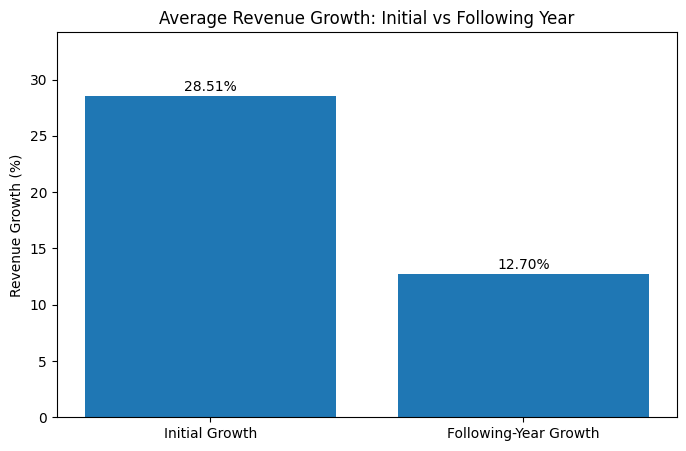

In [15]:

# STEP 10: Compare initial and following-year revenue growth

# Create a bar chart comparing the two average growth rates.
# We use the averages already calculated in Step 8.

growth_labels = ['Initial Growth', 'Following-Year Growth']
growth_rates = [average_initial_growth, average_next_growth]

# figsize sets the chart's width and height in inches.
plt.figure(figsize=(8, 5))

# plt.bar() creates a bar chart.
bars = plt.bar(growth_labels, growth_rates)

# Add the percentage value above each bar.
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'{height:.2f}%',
        ha='center'
    )

# Add a title and axis label.
plt.title('Average Revenue Growth: Initial vs Following Year')
plt.ylabel('Revenue Growth (%)')

# Start the vertical axis at zero.
plt.ylim(0, max(growth_rates) * 1.2)

# Display the chart.
plt.show()


In [16]:

# STEP 9: Forecast revenue for an actual company

# Select Adani Ports from our financial dataset.
company_data = revenue_df[
    revenue_df['Ticker'] == 'ADANIPORTS.NS'
].copy()

# Select the latest year with available revenue.
# sort_values() arranges years from oldest to newest.
# dropna() removes rows with missing revenue.
# iloc[-1] selects the last (latest) observation.

latest_data = (
    company_data.dropna(subset=['Revenue'])
    .sort_values('Financial Year')
    .iloc[-1]
)

# Retrieve the company's latest revenue and financial year.
current_revenue = latest_data['Revenue']
current_year = int(latest_data['Financial Year'])

# Convert the historical average growth percentage to decimal.
forecast_growth = average_next_growth / 100

# Forecast next year's revenue.
forecast_revenue = current_revenue * (1 + forecast_growth)

# Convert rupees into crores (1 crore = 10,000,000 rupees).
print("Company: Adani Ports")
print("Current Financial Year:", current_year)
print("Current Revenue: ₹", round(current_revenue / 1e7, 2), "crore")
print("Forecast Financial Year:", current_year + 1)
print("Assumed Growth:", round(average_next_growth, 2), "%")
print("Forecast Revenue: ₹", round(forecast_revenue / 1e7, 2), "crore")


Company: Adani Ports
Current Financial Year: 2026
Current Revenue: ₹ 38735.77 crore
Forecast Financial Year: 2027
Assumed Growth: 12.7 %
Forecast Revenue: ₹ 43655.74 crore


How many years can high revenue growth continue?

In [17]:
# Set the minimum growth rate considered high growth
growth_threshold = 20

# Mark company-years with revenue growth of at least 20%
revenue_df['High_Growth'] = revenue_df['Revenue_Growth'] >= growth_threshold

# Display the growth pattern for each company, in chronological order
revenue_df[
    ['Ticker', 'Financial Year', 'Revenue_Growth', 'High_Growth']
].head(20)

,Ticker,Financial Year,Revenue_Growth,High_Growth
0,ADANIENT.NS,2023,NaN,False
1,ADANIENT.NS,2024,-24.392484,False
2,ADANIENT.NS,2025,1.448283,False
3,ADANIENT.NS,2026,2.615814,False
4,ADANIPORTS.NS,2022,NaN,False
5,ADANIPORTS.NS,2023,NaN,False
6,ADANIPORTS.NS,2024,28.096467,True
7,ADANIPORTS.NS,2025,14.094688,False
8,ADANIPORTS.NS,2026,27.105334,True
9,APOLLOHOSP.NS,2022,NaN,False


In [21]:
# STEP 1: Find whether each company had high growth in its previous recorded year
# shift(1) moves the High_Growth values down by one row within each company
# fillna(False) treats the first observation as having no previous high-growth year

# shift(1) looks at the previous row within the same company
# astype('boolean') allows missing values without triggering the warning
previous_high = (
    revenue_df.groupby('Ticker')['High_Growth']
    .shift(1)
    .fillna(False)
    .astype(bool)
)

/tmp/ipykernel_1433/2886722355.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna(False)


In [23]:
# Find the previous financial year for each company
# shift(1) brings the previous recorded year into the current row
revenue_df['Previous_Year_Check'] = (
    revenue_df.groupby('Ticker')['Financial Year'].shift(1)
)

# Check whether the difference between the two years is exactly 1
# Example: 2025 - 2024 = 1 (consecutive)
# Example: 2025 - 2023 = 2 (not consecutive)
revenue_df['Consecutive_Year'] = (
    revenue_df['Financial Year'] - revenue_df['Previous_Year_Check'] == 1
)

# Display the result for Adani Ports
revenue_df.loc[
    revenue_df['Ticker'] == 'ADANIPORTS.NS',
    ['Financial Year', 'Previous_Year_Check', 'Consecutive_Year']
]

,Financial Year,Previous_Year_Check,Consecutive_Year
4,2022,NaN,False
5,2023,2022.0,True
6,2024,2023.0,True
7,2025,2024.0,True
8,2026,2025.0,True


In [27]:
# Get the previous year's high-growth status for each company
# shift(1) brings the previous observation into the current row
# fillna(False) handles companies with no previous observation

revenue_df['Previous_High'] = (
    revenue_df.groupby('Ticker')['High_Growth']
    .shift(1)
    .astype('boolean')
    .fillna(False)
)

# Display the result for Adani Ports
revenue_df.loc[
    revenue_df['Ticker'] == 'ADANIPORTS.NS',
    ['Financial Year', 'High_Growth', 'Previous_High', 'Consecutive_Year']
]

,Financial Year,High_Growth,Previous_High,Consecutive_Year
4,2022,False,False,False
5,2023,False,False,True
6,2024,True,False,True
7,2025,False,True,True
8,2026,True,False,True


 Identify when a new high-growth period begin

In [29]:
# Check whether the current year has high growth
# AND whether high growth was absent in the previous year
# OR the previous recorded year was not consecutive

revenue_df['New_Streak'] = (
    revenue_df['High_Growth']
    & (
        ~revenue_df['Previous_High'].fillna(False)
        | ~revenue_df['Consecutive_Year']
    )
)

# Display Adani Ports' results
revenue_df.loc[
    revenue_df['Ticker'] == 'ADANIPORTS.NS',
    ['Financial Year', 'High_Growth', 'Previous_High',
     'Consecutive_Year', 'New_Streak']
]

,Financial Year,High_Growth,Previous_High,Consecutive_Year,New_Streak
4,2022,False,False,False,False
5,2023,False,False,True,False
6,2024,True,False,True,True
7,2025,False,True,True,False
8,2026,True,False,True,True


Step 4: Number each high-growth period
Now we'll assign a number to every separate high-growth period for each company.

In [30]:
# Group companies separately so their growth periods are not mixed
# cumsum() means cumulative sum: it adds up the True values
# In Python, True = 1 and False = 0

revenue_df['Streak_ID'] = (
    revenue_df.groupby('Ticker')['New_Streak'].cumsum()
)

# Example for Adani Ports:
# 2024: New_Streak = True  → Streak_ID = 1
# 2025: New_Streak = False → Streak_ID remains 1
# 2026: New_Streak = True  → Streak_ID = 2

# Display the results for Adani Ports
revenue_df.loc[
    revenue_df['Ticker'] == 'ADANIPORTS.NS',
    ['Financial Year', 'High_Growth', 'New_Streak', 'Streak_ID']
]

,Financial Year,High_Growth,New_Streak,Streak_ID
4,2022,False,False,0
5,2023,False,False,0
6,2024,True,True,1
7,2025,False,False,1
8,2026,True,True,2


In [31]:
# Select only observations where revenue growth is at least 20%
# We exclude False rows because they are not part of a high-growth period

high_growth_only = revenue_df[revenue_df['High_Growth']].copy()

# Group by company and streak number
# transform('count') counts how many years belong to each streak
# Example: If 2024 and 2025 are in streak 1, both receive a length of 2

high_growth_only['Streak_Length'] = (
    high_growth_only.groupby(['Ticker', 'Streak_ID'])['Financial Year']
    .transform('count')
)

# Display the results
high_growth_only[
    ['Ticker', 'Financial Year', 'Revenue_Growth',
     'Streak_ID', 'Streak_Length']
].head(20)

,Ticker,Financial Year,Revenue_Growth,Streak_ID,Streak_Length
6,ADANIPORTS.NS,2024,28.096467,1,1
8,ADANIPORTS.NS,2026,27.105334,2,1
20,AXISBANK.NS,2024,22.730127,1,1
24,BAJAJ-AUTO.NS,2024,23.707826,1,1
26,BAJAJ-AUTO.NS,2026,22.569857,2,1
29,BAJAJFINSV.NS,2024,35.254690,1,2
30,BAJAJFINSV.NS,2025,20.846401,1,2
33,BAJFINANCE.NS,2024,27.290567,1,2
34,BAJFINANCE.NS,2025,20.838966,1,2
45,BHARTIARTL.NS,2026,21.960029,1,1


Interpretation: Streak_Length = 2 means the company maintained growth of at least 20% for two consecutive observed years.

Calculate the average duration of high growth
We must count each high-growth period only once, even if it lasted multiple years.

In [33]:
# STEP 1: Keep one observation for each high-growth period
# drop_duplicates() prevents counting the same streak multiple times
growth_periods = high_growth_only[
    ['Ticker', 'Streak_ID', 'Streak_Length']
].drop_duplicates()

# STEP 2: Calculate the average duration across all growth periods
# mean() calculates the arithmetic average
average_duration = growth_periods['Streak_Length'].mean()

# STEP 3: Display the number of periods and their average duration
print("Number of high-growth periods:", len(growth_periods))
print("Average observed duration:", round(average_duration, 2), "years")

# STEP 4: Show how many periods lasted 1 year, 2 years, etc.
print("\nDistribution of high-growth duration:")
print(growth_periods['Streak_Length'].value_counts().sort_index())

Number of high-growth periods: 23
Average observed duration: 1.22 years

Distribution of high-growth duration:
Streak_Length
1    19
2     3
3     1
Name: count, dtype: int64


What this tells us: How many consecutive years companies maintained revenue growth of at least 20%, on average, within our available data.

The average observed duration is 1.22 years.

This means most high-growth periods in our dataset were observed for only one year. Only four lasted two or more consecutive years.

What can we conclude for Question 1?
Companies experiencing revenue growth of at least 20% showed an average observed high-growth duration of 1.22 years in our sample.

Question 2:

“How do we forecast a company’s operating margin that has been reported either very high (or very low) in the recent past?”

First, a simple example:

A company earns ₹20 crore in operating profit (EBIT) on ₹100 crore in revenue. Its operating margin is 20%.

We'll calculate:
\[
\text{Operating Margin}=\frac{\text{EBIT}}{\text{Revenue}}\times100
\]

Step 1: Calculate operating margins using our dataset

In [34]:
# Select the columns required to calculate operating margins
margin_df = historical_df[
    ['Ticker', 'Company', 'Sector', 'Financial Year', 'Revenue', 'EBIT']
].copy()

# Calculate operating margin as EBIT divided by Revenue
# Multiply by 100 to express the result as a percentage
# Avoid dividing by zero or negative revenue
margin_df['Operating_Margin'] = np.where(
    margin_df['Revenue'] > 0,
    (margin_df['EBIT'] / margin_df['Revenue']) * 100,
    np.nan
)

# Display the first 10 observations
margin_df.head(10)

,Ticker,Company,Sector,Financial Year,Revenue,EBIT,Operating_Margin
0,ADANIENT.NS,Adani Enterprises Limited,Energy,2026,1.002670e+12,1.991757e+11,19.864528
1,ADANIENT.NS,Adani Enterprises Limited,Energy,2025,9.771108e+11,1.536634e+11,15.726302
2,ADANIENT.NS,Adani Enterprises Limited,Energy,2024,9.631615e+11,8.644370e+10,8.974995
3,ADANIENT.NS,Adani Enterprises Limited,Energy,2023,1.273896e+12,6.241290e+10,4.899370
4,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2026,3.873577e+11,1.859993e+11,48.017453
5,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2025,3.047533e+11,1.571630e+11,51.570565
6,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2024,2.671056e+11,1.280524e+11,47.940740
7,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2023,2.085191e+11,8.043950e+10,38.576562
8,ADANIPORTS.NS,Adani Ports and Special Economic Zone Limited,Industrials,2022,NaN,NaN,NaN
9,APOLLOHOSP.NS,Apollo Hospitals Enterprise Limited,Healthcare,2026,2.522850e+11,3.110500e+10,12.329310


Step 2: Identify unusually high and low operating margins

In [39]:
# Classify each observation as Low, High, or Normal
margin_df['Margin_Category'] = np.select(
    [
        margin_df['Operating_Margin'] <= low_margin,
        margin_df['Operating_Margin'] >= high_margin
    ],
    ['Low', 'High'],
    default='Normal'
)

# Display the operating margins and their categories
display(margin_df[
    ['Company', 'Financial Year', 'Operating_Margin', 'Margin_Category']
].head(20))

# Count the number of observations in each category
print(margin_df['Margin_Category'].value_counts())

,Company,Financial Year,Operating_Margin,Margin_Category
0,Adani Enterprises Limited,2026,19.864528,Normal
1,Adani Enterprises Limited,2025,15.726302,Normal
2,Adani Enterprises Limited,2024,8.974995,Normal
3,Adani Enterprises Limited,2023,4.899370,Low
4,Adani Ports and Special Economic Zone Limited,2026,48.017453,High
5,Adani Ports and Special Economic Zone Limited,2025,51.570565,High
6,Adani Ports and Special Economic Zone Limited,2024,47.940740,High
7,Adani Ports and Special Economic Zone Limited,2023,38.576562,Normal
8,Adani Ports and Special Economic Zone Limited,2022,NaN,Normal
9,Apollo Hospitals Enterprise Limited,2026,12.329310,Normal


Margin_Category
Normal    198
Low        17
High       17
Name: count, dtype: int64


Step 3: Find the following year's operating margin
Now we want to know: Do unusually high or low operating margins continue into the next year?

In [40]:
# Sort observations by company and financial year
margin_df = margin_df.sort_values(['Ticker', 'Financial Year'])

# Get each company's following year's operating margin
margin_df['Next_Year_Margin'] = (
    margin_df.groupby('Ticker')['Operating_Margin'].shift(-1)
)

# Get the following financial year to check for gaps
margin_df['Next_Year'] = (
    margin_df.groupby('Ticker')['Financial Year'].shift(-1)
)

# Keep the next-year margin only when years are consecutive
margin_df.loc[
    margin_df['Next_Year'] != margin_df['Financial Year'] + 1,
    'Next_Year_Margin'
] = np.nan

# Display the result
display(margin_df[
    ['Company', 'Financial Year', 'Operating_Margin',
     'Margin_Category', 'Next_Year_Margin']
].head(20))

,Company,Financial Year,Operating_Margin,Margin_Category,Next_Year_Margin
3,Adani Enterprises Limited,2023,4.899370,Low,8.974995
2,Adani Enterprises Limited,2024,8.974995,Normal,15.726302
1,Adani Enterprises Limited,2025,15.726302,Normal,19.864528
0,Adani Enterprises Limited,2026,19.864528,Normal,NaN
8,Adani Ports and Special Economic Zone Limited,2022,NaN,Normal,38.576562
7,Adani Ports and Special Economic Zone Limited,2023,38.576562,Normal,47.940740
6,Adani Ports and Special Economic Zone Limited,2024,47.940740,High,51.570565
5,Adani Ports and Special Economic Zone Limited,2025,51.570565,High,48.017453
4,Adani Ports and Special Economic Zone Limited,2026,48.017453,High,NaN
13,Apollo Hospitals Enterprise Limited,2022,NaN,Normal,8.862376


“An unusually high or low operating margin does not necessarily remain unchanged, nor does it always immediately return to normal.

Adani Enterprises shows improving margins, while Adani Ports demonstrates that high margins can persist.

Therefore, instead of assuming margins will increase or decrease, we examine how companies with similar historical margins performed in subsequent years.”

Step 4: Calculate the average following-year operating margin
Now let's find out what typically happens to companies with High, Low, and Normal operating margins.

In [41]:
# Calculate the average next-year operating margin for each category
margin_summary = (
    margin_df.groupby('Margin_Category')
    .agg(
        Observations=('Next_Year_Margin', 'count'),
        Average_Current_Margin=('Operating_Margin', 'mean'),
        Average_Next_Year_Margin=('Next_Year_Margin', 'mean'),
        Next_Year_Std_Dev=('Next_Year_Margin', 'std')
    )
)

# Display results rounded to 2 decimal places
display(margin_summary.round(2))

,Observations,Average_Current_Margin,Average_Next_Year_Margin,Next_Year_Std_Dev
Margin_Category,,,,
High,13,75.52,68.56,45.03
Low,14,2.41,5.08,3.97
Normal,125,18.43,20.53,21.44


This gives us an interesting result: low operating margins appear to improve, while high operating margins appear to decline.
This suggests a phenomenon called mean reversion: unusually high or low financial performance may gradually move towards more typical levels

Step 5: Compare the same observations

We are checking whether operating margins tend to revert towards more typical levels. This historical pattern can help us forecast future margins, but it is not a guarantee

In [45]:
# Group observations into High, Low and Normal categories
# Calculate the average current and next-year operating margins
matched_summary = matched_margins.groupby('Margin_Category').agg(
    Observations=('Operating_Margin', 'count'),
    Current_Margin=('Operating_Margin', 'mean'),
    Next_Year_Margin=('Next_Year_Margin', 'mean')
)

# STEP 1: Display the averages
display(matched_summary.round(2))

# STEP 2: Calculate the change in average operating margin
# Change = Next-year average margin - Current average margin
# A positive value indicates improvement; negative indicates decline
matched_summary['Change'] = (
    matched_summary['Next_Year_Margin']
    - matched_summary['Current_Margin']
)

# STEP 3: Display the averages along with the change
display(matched_summary.round(2))

,Observations,Current_Margin,Next_Year_Margin
Margin_Category,,,
High,13,79.98,68.56
Low,14,2.46,5.08
Normal,94,18.38,18.89


,Observations,Current_Margin,Next_Year_Margin,Change
Margin_Category,,,,
High,13,79.98,68.56,-11.42
Low,14,2.46,5.08,2.62
Normal,94,18.38,18.89,0.52


Our analysis suggests mean reversion in operating margins.

Companies with unusually high operating margins experienced an average decline of 11.42 percentage points in the following year.

Companies with unusually low margins experienced an average improvement of 2.62 percentage points.

Meanwhile, companies with normal margins remained relatively stable.

This suggests that unusually high or low profitability may not persist indefinitely.”

How does this help us forecast?
Suppose we're forecasting a company with an unusually high operating margin of 80%.

Our historical analysis suggests that margins in this category declined by approximately 11.42 percentage points the following year.

An illustrative forecast would therefore be:
\[
80\%-11.42\%=68.58\%
\]

Step 6: Forecast FY2027 operating margins

In [46]:
# Select FY2026 observations because we want to forecast FY2027
forecast_df = margin_df[
    margin_df['Financial Year'] == 2026
].copy()

# Use the historical average change for each margin category
# High: -11.42 percentage points
# Low: +2.62 percentage points
# Normal: +0.52 percentage points
average_changes = matched_summary['Change']

# Match each company's margin category with its historical average change
forecast_df['Expected_Change'] = (
    forecast_df['Margin_Category'].map(average_changes)
)

# Forecast FY2027 operating margin
# Forecast = FY2026 operating margin + expected historical change
forecast_df['Forecast_2027_Margin'] = (
    forecast_df['Operating_Margin'] + forecast_df['Expected_Change']
)

# Display company-wise forecasts
display(forecast_df[
    ['Company', 'Margin_Category', 'Operating_Margin',
     'Expected_Change', 'Forecast_2027_Margin']
].round(2))

,Company,Margin_Category,Operating_Margin,Expected_Change,Forecast_2027_Margin
0,Adani Enterprises Limited,Normal,19.86,0.52,20.38
4,Adani Ports and Special Economic Zone Limited,High,48.02,-11.42,36.59
9,Apollo Hospitals Enterprise Limited,Normal,12.33,0.52,12.84
14,Asian Paints Limited,Normal,17.44,0.52,17.96
18,NaN,Normal,NaN,0.52,NaN
23,Bajaj Auto Limited,Normal,25.04,0.52,25.55
31,Bajaj Finserv Ltd.,High,40.19,-11.42,28.76
27,Bajaj Finance Limited,Normal,NaN,0.52,NaN
36,Bharat Electronics Limited,Normal,29.19,0.52,29.71
41,Bharti Airtel Limited,Normal,29.87,0.52,30.38


We are using the average historical change experienced by similar-margin companies to estimate each company's FY2027 operating margin.

This is a simple category-based forecast. It assumes historical patterns continue and doesn't yet account for industry-specific differences.